## Exploratory Data Analysis

### 1. Dataset Overview

Initial inspection of the cleaned dataset before starting the exploratory analysis.

In [1]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
cleaned_path = Path(
        "data/cleaned/istat_traffic_2020_2024_cleaned.csv"
    )

df = pd.read_csv(cleaned_path, keep_default_na=False, na_values=[""])

In [3]:
df.shape

(39507, 13)

In [4]:
df.head()

,REF_AREA,municipality,region_code,province_code,province_abbr,area_km2,population,TIME_PERIOD,accidents,injured,killed,accidents_per_100k,accidents_per_km2
0,1001,Agliè,1,201,TO,13.1462,2545,2020,4,4,0,157.170923,0.304270
1,1002,Airasca,1,201,TO,15.7393,3633,2020,8,14,0,220.203688,0.508282
2,1003,Ala di Stura,1,201,TO,46.3315,459,2020,0,0,0,0.000000,0.000000
3,1004,Albiano d'Ivrea,1,201,TO,11.7314,1638,2020,3,3,0,183.150183,0.255724
4,1006,Almese,1,201,TO,17.8756,6355,2020,6,8,0,94.413847,0.335653


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 39507 entries, 0 to 39506
Data columns (total 13 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   REF_AREA            39507 non-null  int64  
 1   municipality        39507 non-null  str    
 2   region_code         39507 non-null  int64  
 3   province_code       39507 non-null  int64  
 4   province_abbr       39507 non-null  str    
 5   area_km2            39507 non-null  float64
 6   population          39507 non-null  int64  
 7   TIME_PERIOD         39507 non-null  int64  
 8   accidents           39507 non-null  int64  
 9   injured             39507 non-null  int64  
 10  killed              39507 non-null  int64  
 11  accidents_per_100k  39507 non-null  float64
 12  accidents_per_km2   39507 non-null  float64
dtypes: float64(3), int64(8), str(2)
memory usage: 3.9 MB


In [6]:
df.isna().sum()

REF_AREA              0
municipality          0
region_code           0
province_code         0
province_abbr         0
area_km2              0
population            0
TIME_PERIOD           0
accidents             0
injured               0
killed                0
accidents_per_100k    0
accidents_per_km2     0
dtype: int64

### 2. Descriptive Statistics

Summary statistics for the main numerical variables in the dataset.

In [7]:
df[
    [
        "area_km2",
        "population",
        "accidents",
        "injured",
        "killed",
        "accidents_per_100k",
        "accidents_per_km2"
    ]
].describe()

,area_km2,population,accidents,injured,killed,accidents_per_100k,accidents_per_km2
count,39507.000000,3.950700e+04,39507.000000,39507.000000,39507.000000,39507.000000,39507.000000
mean,38.233896,7.471543e+03,19.640848,26.474751,0.366973,167.673869,0.574534
std,50.815284,4.161772e+04,180.855157,227.501583,1.923311,185.782998,1.527321
min,0.120600,2.900000e+01,0.000000,0.000000,0.000000,0.000000,0.000000
25%,11.455650,9.810000e+02,1.000000,1.000000,0.000000,44.146862,0.022169
50%,22.438000,2.399000e+03,3.000000,4.000000,0.000000,135.379061,0.134616
75%,44.718950,6.238000e+03,10.000000,15.000000,0.000000,236.520377,0.479180
max,1288.187500,2.770226e+06,13924.000000,17196.000000,154.000000,8510.638298,42.959663


The descriptive statistics show substantial variation across Italian municipalities.

Accidents, injuries, population and the normalised accident indicators are strongly right-skewed, with maximum values considerably higher than their medians.

Fatalities are relatively uncommon at municipality-year level, with the median and 75th percentile both equal to zero.

The very high maximum values for accidents per 100,000 residents and accidents per square kilometre suggest that extreme observations should be investigated later in the analysis.

In [8]:
# maximum values

df.nlargest(
    10,
    "accidents_per_100k"
)[
    [
        "municipality",
        "TIME_PERIOD",
        "population",
        "accidents",
        "accidents_per_100k"
    ]
]

,municipality,TIME_PERIOD,population,accidents,accidents_per_100k
15960,Moncenisio,2022,47,4,8510.638298
32097,Argentera,2024,77,3,3896.103896
31123,Morterone,2023,33,1,3030.303030
24751,Bard,2023,102,3,2941.176471
31061,Villanova Biellese,2023,175,5,2857.142857
645,Pietraporzio,2020,74,2,2702.702703
34758,Colle Santa Lucia,2024,340,9,2647.058824
25028,Carrodano,2023,465,12,2580.645161
11574,Cerignale,2021,117,3,2564.102564
7212,Baradili,2020,80,2,2500.000000


In [9]:
df.nlargest(
    10,
    "accidents_per_km2"
)[
    [
        "municipality",
        "TIME_PERIOD",
        "area_km2",
        "population",
        "accidents",
        "accidents_per_km2"
    ]
]

,municipality,TIME_PERIOD,area_km2,population,accidents,accidents_per_km2
25483,Milano,2023,181.8450,1371499,7812,42.959663
17582,Milano,2022,181.8450,1358420,7783,42.800187
33382,Milano,2024,181.8450,1365698,7743,42.580219
9678,Milano,2021,181.8450,1349930,7465,41.051445
33353,Cormano,2024,4.4733,20744,126,28.167125
25449,Cinisello Balsamo,2023,12.7240,74741,353,27.742848
17622,Sesto San Giovanni,2022,11.6989,79143,323,27.609433
33348,Cinisello Balsamo,2024,12.7240,74702,348,27.349890
1775,Milano,2020,181.6783,1374582,4856,26.728564
1748,Corsico,2020,5.3556,34601,143,26.701023


In [10]:
# Validate accidents per km² calculation

df["accidents_per_km2_check"] = (
    df["accidents"] / df["area_km2"]
)

np.allclose(
    df["accidents_per_km2"],
    df["accidents_per_km2_check"]
)

True

In [11]:
# Remove temporary validation column

df.drop(columns="accidents_per_km2_check", inplace=True)

### Extreme values

The highest accident rates per square kilometre are mainly found in densely populated urban municipalities.

Milan appears repeatedly among the highest values because a large number of accidents occurs within a relatively limited municipal area.

Unlike the extreme values observed for accidents per 100,000 residents, these values appear to be driven mainly by high accident volumes and urban density rather than very small population denominators.

## 3. Accident Trends 2020–2024

Analysis of how the total number of road accidents changed over time.

In [12]:
accidents_by_year = (
    df.groupby("TIME_PERIOD")["accidents"]
    .sum()
)
accidents_by_year

TIME_PERIOD
2020    118298
2021    151875
2022    165889
2023    166525
2024    173364
Name: accidents, dtype: int64

In [13]:
# Year-over-Year (YoY) Accident Growth (%)

accident_trend = accidents_by_year.to_frame()
accident_trend["pct_change"] = (accident_trend["accidents"].pct_change() * 100)
accident_trend.round(2)

,accidents,pct_change
TIME_PERIOD,,
2020,118298,NaN
2021,151875,28.38
2022,165889,9.23
2023,166525,0.38
2024,173364,4.11


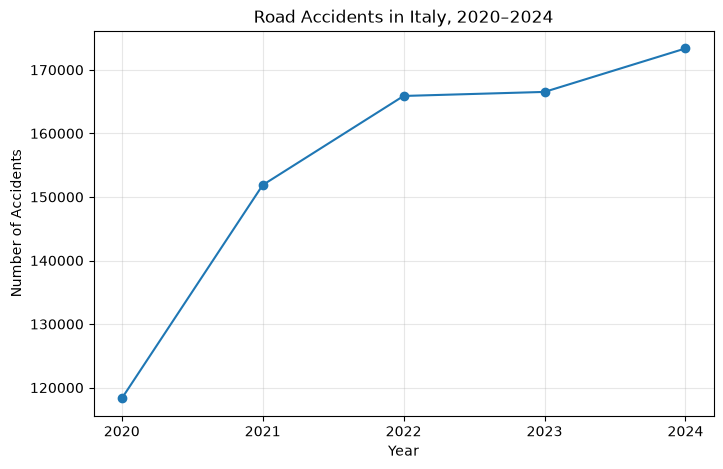

In [14]:
# Road Accident Trend (2020–2024)

plt.figure(figsize=(8, 5))

plt.plot(
    accidents_by_year.index,
    accidents_by_year.values,
    marker="o"
)

plt.title("Road Accidents in Italy, 2020–2024")
plt.xlabel("Year")
plt.ylabel("Number of Accidents")
plt.xticks(accidents_by_year.index)
plt.grid(alpha=0.3)

plt.show()

In [15]:
# Annual Injuries and Fatalities (2020–2024)

casualties_by_year = (
    df.groupby("TIME_PERIOD")[["injured", "killed"]]
      .sum()
)

casualties_by_year

,injured,killed
TIME_PERIOD,,
2020,159248,2395
2021,204728,2875
2022,223475,3159
2023,224634,3039
2024,233853,3030


In [16]:
casualties_trend = casualties_by_year.copy()

casualties_trend["injured_pct_change"] = (
    casualties_trend["injured"].pct_change() * 100
)

casualties_trend["killed_pct_change"] = (
    casualties_trend["killed"].pct_change() * 100
)

casualties_trend.round(2)

,injured,killed,injured_pct_change,killed_pct_change
TIME_PERIOD,,,,
2020,159248,2395,NaN,NaN
2021,204728,2875,28.56,20.04
2022,223475,3159,9.16,9.88
2023,224634,3039,0.52,-3.80
2024,233853,3030,4.10,-0.30


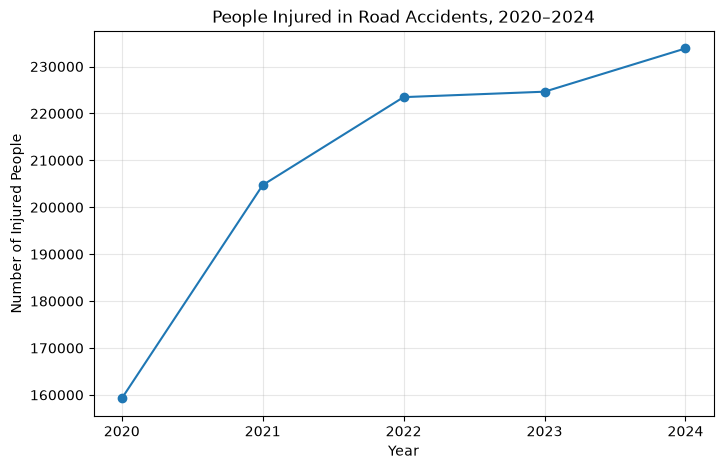

In [17]:
plt.figure(figsize=(8, 5))

plt.plot(
    casualties_by_year.index,
    casualties_by_year["injured"],
    marker="o"
)

plt.title("People Injured in Road Accidents, 2020–2024")
plt.xlabel("Year")
plt.ylabel("Number of Injured People")
plt.xticks(casualties_by_year.index)
plt.grid(alpha=0.3)

plt.show()

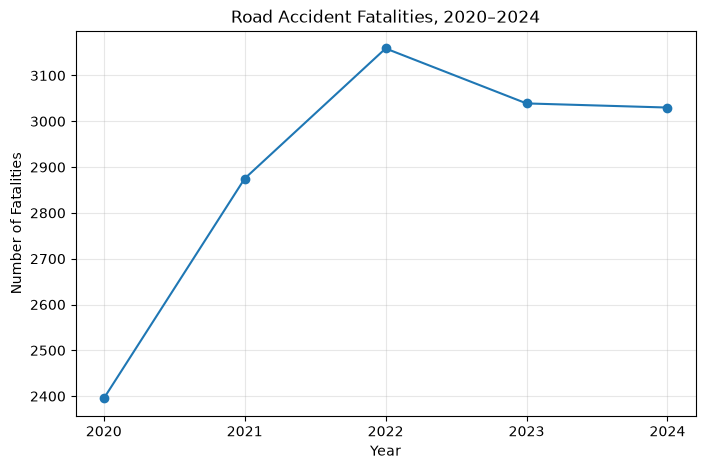

In [18]:
plt.figure(figsize=(8, 5))

plt.plot(
    casualties_by_year.index,
    casualties_by_year["killed"],
    marker="o"
)

plt.title("Road Accident Fatalities, 2020–2024")
plt.xlabel("Year")
plt.ylabel("Number of Fatalities")
plt.xticks(casualties_by_year.index)
plt.grid(alpha=0.3)

plt.show()

### Casualty trend observations

The number of injured people increased across the 2020–2024 period, with the strongest growth occurring between 2020 and 2021.

Fatalities followed a different pattern. They increased until 2022, then declined slightly in 2023 and 2024.

This shows that the increase in accidents and injuries was not accompanied by a proportional increase in fatalities.

## 4. Accidents by Municipality

Comparison of municipalities based on total road accidents recorded across the 2020–2024 period.

In [19]:
accidents_by_municipality = (
    df.groupby("municipality")["accidents"]
      .sum()
      .sort_values(ascending=False)
)

accidents_by_municipality.head(10)

municipality
Roma       59280
Milano     35659
Genova     17875
Torino     13702
Napoli     11219
Firenze    11019
Bologna     9461
Palermo     8633
Bari        7384
Catania     6333
Name: accidents, dtype: int64

In [20]:
top_municipalities = (
    df.groupby(["REF_AREA", "municipality"])["accidents"]
      .sum()
      .sort_values(ascending=False)
      .head(10)
      .reset_index()
)

top_municipalities

,REF_AREA,municipality,accidents
0,58091,Roma,59280
1,15146,Milano,35659
2,10025,Genova,17875
3,1272,Torino,13702
4,63049,Napoli,11219
5,48017,Firenze,11019
6,37006,Bologna,9461
7,82053,Palermo,8633
8,72006,Bari,7384
9,87015,Catania,6333


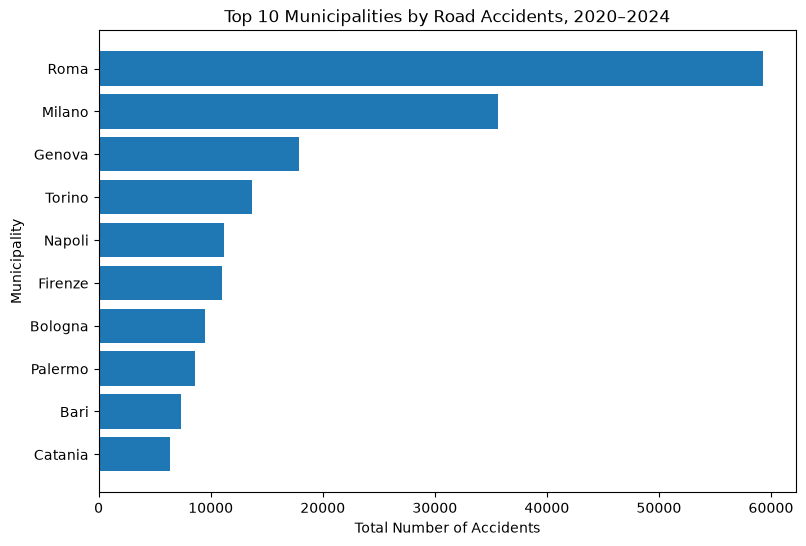

In [21]:
plt.figure(figsize=(9, 6))

plt.barh(
    top_municipalities["municipality"],
    top_municipalities["accidents"]
)

plt.title("Top 10 Municipalities by Road Accidents, 2020–2024")
plt.xlabel("Total Number of Accidents")
plt.ylabel("Municipality")

plt.gca().invert_yaxis()

plt.show()

In [22]:
# Comparison of Accident Rates Adjusted by Population (2020–2024)

accidents_rate_by_municipality = (
    df.groupby(["REF_AREA", "municipality"])
      .agg(
          total_accidents=("accidents", "sum"),
          population_years=("population", "sum"),
          avg_population=("population", "mean")
      )
      .reset_index()
)

accidents_rate_by_municipality["accidents_per_100k"] = (
    accidents_rate_by_municipality["total_accidents"]
    / accidents_rate_by_municipality["population_years"]
    * 100_000
)

accidents_rate_by_municipality.sort_values(
    "accidents_per_100k",
    ascending=False
).head(10)

,REF_AREA,municipality,total_accidents,population_years,avg_population,accidents_per_100k
153,1157,Moncenisio,6,226,45.2,2654.867257
486,4006,Argentera,6,393,78.6,1526.717557
5528,66083,Rocca Pia,13,880,176.0,1477.272727
1504,13030,Brienno,24,1626,325.2,1476.014760
645,4167,Pietraporzio,5,353,70.6,1416.430595
1323,11010,Carrodano,31,2360,472.0,1313.559322
2721,21065,Ponte Gardena/Waidbruck,14,1074,214.8,1303.538175
4188,46013,Forte dei Marmi,449,34482,6896.4,1302.128647
318,2009,Balocco,14,1080,216.0,1296.296296
7369,96079,Villanova Biellese,11,899,179.8,1223.581758


In [23]:
# Comparison of Accident Rates Adjusted by Population (≥ 5,000 Residents)
top_rate_5000 = (
    accidents_rate_by_municipality[
        accidents_rate_by_municipality["avg_population"] >= 5000
    ]
    .sort_values("accidents_per_100k", ascending=False)
    .head(10)
)

top_rate_5000

,REF_AREA,municipality,total_accidents,population_years,avg_population,accidents_per_100k
4188,46013,Forte dei Marmi,449,34482,6896.4,1302.128647
3852,37005,Bentivoglio,275,28813,5762.6,954.430292
3551,30049,Lignano Sabbiadoro,266,34346,6869.2,774.471554
1300,10054,Santa Margherita Ligure,328,42580,8516.0,770.314702
1867,16024,Bergamo,4182,599824,119964.8,697.204513
1274,10028,Lavagna,429,61684,12336.8,695.480189
4233,48005,Calenzano,596,90640,18128.0,657.546337
1271,10025,Genova,17875,2815306,563061.2,634.922101
7531,99013,Riccione,1079,172864,34572.8,624.190115
1716,15011,Assago,286,46183,9236.6,619.275491


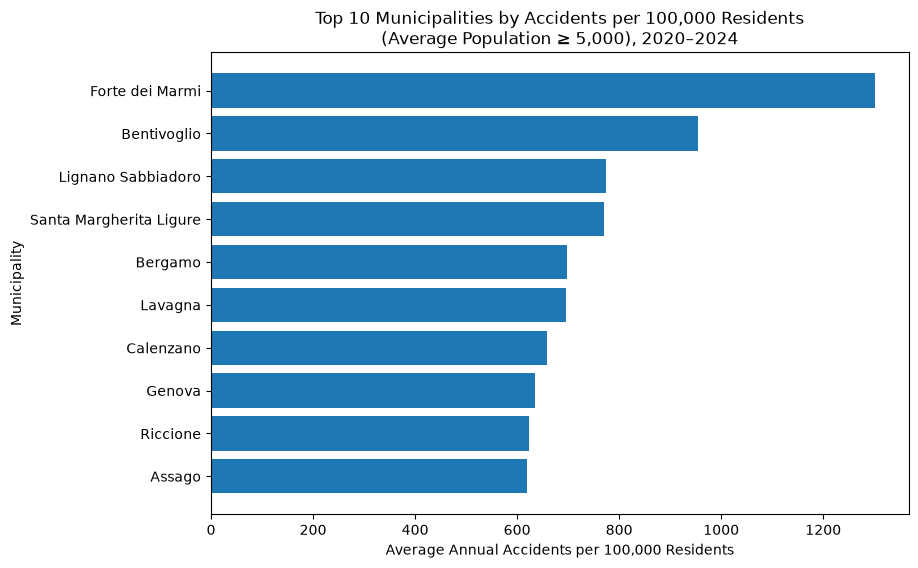

In [24]:
plt.figure(figsize=(9, 6))

plt.barh(
    top_rate_5000["municipality"],
    top_rate_5000["accidents_per_100k"]
)

plt.title(
    "Top 10 Municipalities by Accidents per 100,000 Residents\n"
    "(Average Population ≥ 5,000), 2020–2024"
)
plt.xlabel("Average Annual Accidents per 100,000 Residents")
plt.ylabel("Municipality")

plt.gca().invert_yaxis()

plt.show()

### Population-adjusted comparison

The unfiltered ranking is strongly influenced by municipalities with very small populations.

As an exploratory comparison, municipalities with an average population of at least 5,000 residents are also examined.

This threshold reduces the influence of very small population denominators and makes it easier to compare municipalities with larger resident populations.

Forte dei Marmi records the highest accident rate within this filtered group.

## 5. Accidents per Square Kilometre

Comparison of municipalities based on the average annual number of road accidents per square kilometre during 2020–2024.

In [25]:
accidents_density_by_municipality = (
    df.groupby(["REF_AREA", "municipality"])
      .agg(
          total_accidents=("accidents", "sum"),
          years_observed=("TIME_PERIOD", "nunique"),
          avg_area_km2=("area_km2", "mean")
      )
      .reset_index()
)

accidents_density_by_municipality["avg_annual_accidents"] = (
    accidents_density_by_municipality["total_accidents"]
    / accidents_density_by_municipality["years_observed"]
)

accidents_density_by_municipality["accidents_per_km2"] = (
    accidents_density_by_municipality["avg_annual_accidents"]
    / accidents_density_by_municipality["avg_area_km2"]
)

top_density_municipalities = (
    accidents_density_by_municipality
    .sort_values("accidents_per_km2", ascending=False)
    .head(10)
)

top_density_municipalities

,REF_AREA,municipality,total_accidents,years_observed,avg_area_km2,avg_annual_accidents,accidents_per_km2
1782,15146,Milano,35659,5,181.81166,7131.8,39.226307
1748,15077,Cinisello Balsamo,1392,5,12.72402,278.4,21.879878
4242,48017,Firenze,11019,5,102.30928,2203.8,21.540568
267,1272,Torino,13702,5,130.04548,2740.4,21.072628
1867,16024,Bergamo,4182,5,40.22470,836.4,20.793194
1755,15093,Corsico,553,5,5.36392,110.6,20.619249
1753,15086,Cormano,432,5,4.47332,86.4,19.314514
5126,63049,Napoli,11219,5,119.18266,2243.8,18.826564
1822,15209,Sesto San Giovanni,1018,5,11.69896,203.6,17.403256
5136,63059,Portici,371,5,4.62914,74.2,16.028895


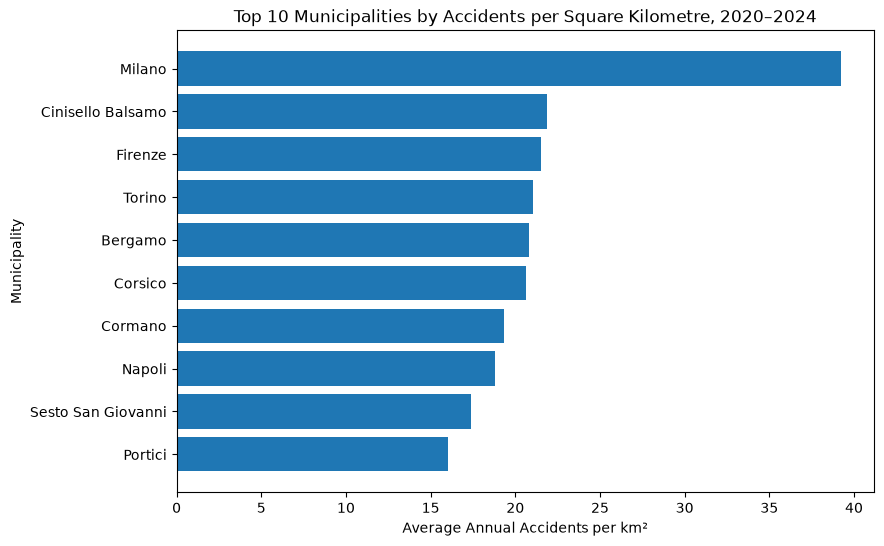

In [26]:
plt.figure(figsize=(9, 6))

plt.barh(
    top_density_municipalities["municipality"],
    top_density_municipalities["accidents_per_km2"]
)

plt.title(
    "Top 10 Municipalities by Accidents per Square Kilometre, 2020–2024"
)
plt.xlabel("Average Annual Accidents per km²")
plt.ylabel("Municipality")

plt.gca().invert_yaxis()

plt.show()

### Accident density observations

The highest average annual accident densities are concentrated in large
urban or geographically compact municipalities.

Milan records the highest accident density over the 2020–2024 period.

This indicator highlights a different pattern from accidents per 100,000
residents: high values are mainly associated with a large number of
accidents occurring within a relatively small municipal area.

## 6. Injuries and Fatalities by Municipality

Comparison of municipalities based on the total number of injured people and fatalities recorded during 2020–2024.

In [27]:
casualties_by_municipality = (
    df.groupby(["REF_AREA", "municipality"])
      .agg(
          total_accidents=("accidents", "sum"),
          total_injured=("injured", "sum"),
          total_killed=("killed", "sum")
      )
      .reset_index()
)

casualties_by_municipality.head()

,REF_AREA,municipality,total_accidents,total_injured,total_killed
0,1001,Agliè,14,22,1
1,1002,Airasca,30,47,1
2,1003,Ala di Stura,2,3,0
3,1004,Albiano d'Ivrea,15,22,0
4,1006,Almese,21,26,1


In [28]:
top_injured_municipalities = (
    casualties_by_municipality
    .sort_values("total_injured", ascending=False)
    .head(10)
)

top_injured_municipalities

,REF_AREA,municipality,total_accidents,total_injured,total_killed
4741,58091,Roma,59280,74151,663
1782,15146,Milano,35659,44480,191
1271,10025,Genova,17875,21161,80
267,1272,Torino,13702,19469,99
5126,63049,Napoli,11219,14417,157
4242,48017,Firenze,11019,12907,61
3853,37006,Bologna,9461,11934,81
6618,82053,Palermo,8633,11205,106
5901,72006,Bari,7384,10611,58
6855,87015,Catania,6333,8714,73


In [29]:
top_killed_municipalities = (
    casualties_by_municipality
    .sort_values("total_killed", ascending=False)
    .head(10)
)

top_killed_municipalities

,REF_AREA,municipality,total_accidents,total_injured,total_killed
4741,58091,Roma,59280,74151,663
1782,15146,Milano,35659,44480,191
5126,63049,Napoli,11219,14417,157
6618,82053,Palermo,8633,11205,106
267,1272,Torino,13702,19469,99
3853,37006,Bologna,9461,11934,81
1271,10025,Genova,17875,21161,80
6855,87015,Catania,6333,8714,73
4242,48017,Firenze,11019,12907,61
3029,23091,Verona,5649,6944,61


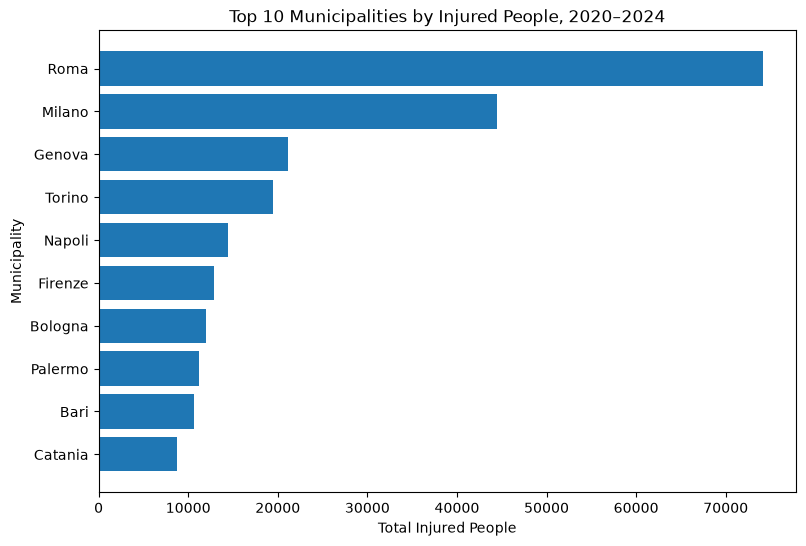

In [30]:
plt.figure(figsize=(9, 6))

plt.barh(
    top_injured_municipalities["municipality"],
    top_injured_municipalities["total_injured"]
)

plt.title("Top 10 Municipalities by Injured People, 2020–2024")
plt.xlabel("Total Injured People")
plt.ylabel("Municipality")

plt.gca().invert_yaxis()

plt.show()

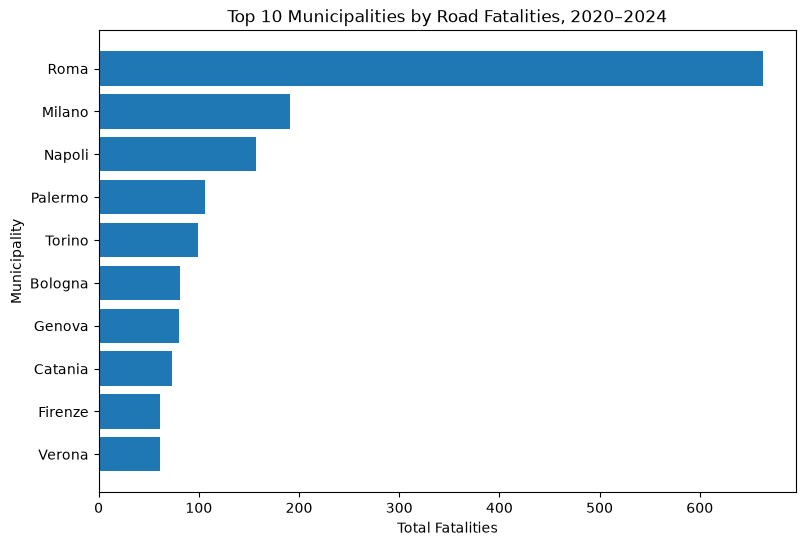

In [31]:
plt.figure(figsize=(9, 6))

plt.barh(
    top_killed_municipalities["municipality"],
    top_killed_municipalities["total_killed"]
)

plt.title("Top 10 Municipalities by Road Fatalities, 2020–2024")
plt.xlabel("Total Fatalities")
plt.ylabel("Municipality")

plt.gca().invert_yaxis()

plt.show()

### Injury and fatality observations

Municipalities with the highest numbers of accidents also tend to record
high numbers of injured people and fatalities.

However, the rankings are not identical. Some municipalities rank higher
for fatalities than for injuries, indicating that accident frequency alone
does not fully describe accident severity.

A severity-based indicator can therefore provide additional insight.

## 7. Accident Severity

The mortality index is used to compare accident severity across municipalities.

It is calculated as the number of fatalities per 100 road accidents.

Because mortality rates can become unstable when based on very small numbers
of accidents, minimum accident thresholds are used to test the robustness
of the municipality ranking.

In [32]:
severity_by_municipality = casualties_by_municipality.copy()

severity_by_municipality["mortality_index"] = (
    severity_by_municipality["total_killed"]
    / severity_by_municipality["total_accidents"]
    * 100
)

In [33]:
severity_100 = (
    severity_by_municipality[
        severity_by_municipality["total_accidents"] >= 100
    ]
    .sort_values("mortality_index", ascending=False)
    .head(10)
)

severity_100

,REF_AREA,municipality,total_accidents,total_injured,total_killed,mortality_index
5956,73019,Mottola,107,238,27,25.233645
4781,59010,Itri,102,130,12,11.764706
6241,78029,Cassano all'Ionio,128,235,13,10.156250
3382,28033,Codevigo,143,261,14,9.790210
4788,59017,Pontinia,215,340,21,9.767442
3334,27027,Noventa di Piave,113,174,11,9.734513
5946,73009,Laterza,150,266,14,9.333333
3184,25040,Ponte nelle Alpi,103,132,9,8.737864
4850,60046,Paliano,115,189,10,8.695652
5870,71036,Orta Nova,129,240,11,8.527132


In [34]:
severity_500 = (
    severity_by_municipality[
        severity_by_municipality["total_accidents"] >= 500
    ]
    .sort_values("mortality_index", ascending=False)
    .head(10)
)

severity_500

,REF_AREA,municipality,total_accidents,total_injured,total_killed,mortality_index
5884,71051,San Severo,735,1223,45,6.122449
5855,71020,Cerignola,752,1401,33,4.388298
5337,65050,Eboli,676,1102,28,4.142012
4697,58047,Guidonia Montecelio,618,867,23,3.721683
5111,63034,Giugliano in Campania,888,1292,33,3.716216
2153,17067,Desenzano del Garda,548,735,20,3.649635
5312,65025,Capaccio Paestum,578,887,21,3.633218
6904,88006,Modica,605,912,20,3.305785
6910,88012,Vittoria,842,1313,26,3.087886
6363,78157,Corigliano-Rossano,625,1058,19,3.040000


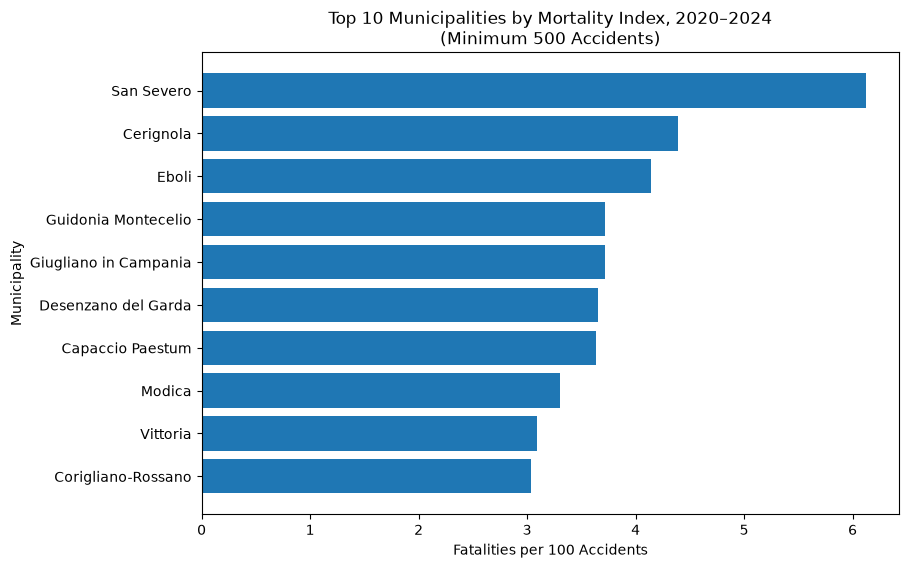

In [35]:
plt.figure(figsize=(9, 6))

plt.barh(
    severity_500["municipality"],
    severity_500["mortality_index"]
)

plt.title(
    "Top 10 Municipalities by Mortality Index, 2020–2024\n"
    "(Minimum 500 Accidents)"
)
plt.xlabel("Fatalities per 100 Accidents")
plt.ylabel("Municipality")

plt.gca().invert_yaxis()

plt.show()

### Severity observations

The municipality ranking changes substantially when the minimum accident
threshold increases from 100 to 500 accidents.

This shows that mortality indices based on relatively small accident totals
can be unstable.

For this exploratory analysis, municipalities with at least 500 accidents are
used for the main severity comparison, while the 100-accident threshold is
retained as a sensitivity check.

## 8. Outliers and Extreme Values

This section investigates unusually high or low values in the main accident indicators.

Extreme observations are examined to determine whether they represent
potential data issues or genuine characteristics of particular municipalities.

In [36]:
outlier_columns = [
    "accidents",
    "injured",
    "killed",
    "accidents_per_100k",
    "accidents_per_km2"
]

df[outlier_columns].describe()

,accidents,injured,killed,accidents_per_100k,accidents_per_km2
count,39507.000000,39507.000000,39507.000000,39507.000000,39507.000000
mean,19.640848,26.474751,0.366973,167.673869,0.574534
std,180.855157,227.501583,1.923311,185.782998,1.527321
min,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1.000000,1.000000,0.000000,44.146862,0.022169
50%,3.000000,4.000000,0.000000,135.379061,0.134616
75%,10.000000,15.000000,0.000000,236.520377,0.479180
max,13924.000000,17196.000000,154.000000,8510.638298,42.959663


In [37]:
q1 = df["accidents"].quantile(0.25)
q3 = df["accidents"].quantile(0.75)

iqr = q3 - q1

lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

print("Q1:", q1)
print("Q3:", q3)
print("IQR:", iqr)
print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)

Q1: 1.0
Q3: 10.0
IQR: 9.0
Lower bound: -12.5
Upper bound: 23.5


In [38]:
accident_outliers = df[
    (df["accidents"] < lower_bound) |
    (df["accidents"] > upper_bound)
]

print("Number of potential outliers:", len(accident_outliers))

Number of potential outliers: 5067


In [39]:
accident_outliers[
    [
        "municipality",
        "TIME_PERIOD",
        "population",
        "accidents"
    ]
].sort_values(
    "accidents",
    ascending=False
).head(20)

,municipality,TIME_PERIOD,population,accidents
36330,Roma,2024,2747290,13924
20534,Roma,2022,2755309,13181
28434,Roma,2023,2751747,12817
12630,Roma,2021,2749031,11129
4729,Roma,2020,2770226,8229
25483,Milano,2023,1371499,7812
17582,Milano,2022,1358420,7783
33382,Milano,2024,1365698,7743
9678,Milano,2021,1349930,7465
1775,Milano,2020,1374582,4856


### Accident outliers

The IQR method identifies 5,067 municipality-year observations as potential
outliers for the number of road accidents.

However, the largest values are concentrated mainly in major urban
municipalities such as Rome, Milan, Genoa and Turin.

These observations appear to represent genuine differences in accident
volume rather than data errors and are therefore retained in the analysis.

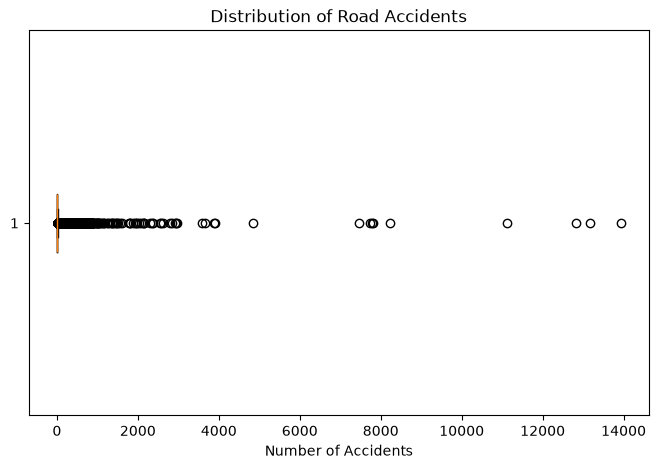

In [40]:
plt.figure(figsize=(8, 5))

plt.boxplot(
    df["accidents"],
    orientation="horizontal"
)

plt.title("Distribution of Road Accidents")
plt.xlabel("Number of Accidents")

plt.show()

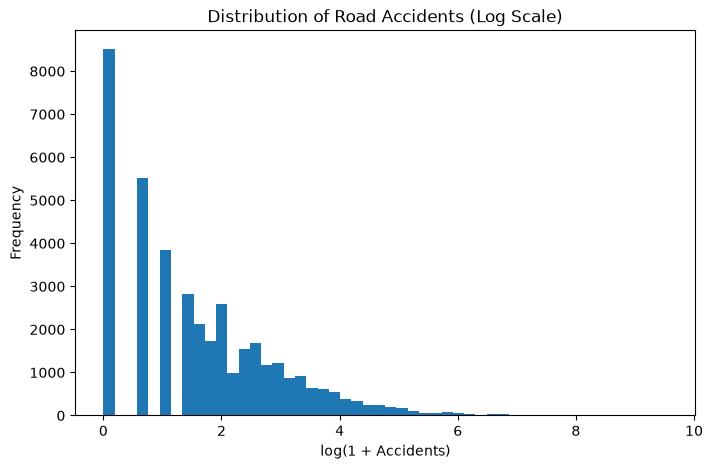

In [41]:
plt.figure(figsize=(8, 5))

plt.hist(
    np.log1p(df["accidents"]),
    bins=50
)

plt.title("Distribution of Road Accidents (Log Scale)")
plt.xlabel("log(1 + Accidents)")
plt.ylabel("Frequency")

plt.show()

### Distribution observations

The distribution of road accidents is strongly right-skewed.

Most municipality-year observations record relatively few accidents,
while a small number of large urban municipalities record substantially
higher values.

The extreme observations are retained because they appear to reflect
genuine differences between municipalities rather than data errors.

A logarithmic transformation is used only to improve visualisation of
the distribution; the original accident values remain unchanged.

In [42]:
# IQR-Based Outlier Detection Function

def iqr_summary(data, column):
    q1 = data[column].quantile(0.25)
    q3 = data[column].quantile(0.75)
    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outliers = data[
        (data[column] < lower_bound) |
        (data[column] > upper_bound)
    ]

    return {
        "column": column,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "lower_bound": lower_bound,
        "upper_bound": upper_bound,
        "outliers": len(outliers)
    }
for column in [
    "injured",
    "accidents_per_100k",
    "accidents_per_km2"
]:
    print(iqr_summary(df, column))

{'column': 'injured', 'Q1': np.float64(1.0), 'Q3': np.float64(15.0), 'IQR': np.float64(14.0), 'lower_bound': np.float64(-20.0), 'upper_bound': np.float64(36.0), 'outliers': 4700}
{'column': 'accidents_per_100k', 'Q1': np.float64(44.146862132899884), 'Q3': np.float64(236.52037746963185), 'IQR': np.float64(192.37351533673197), 'lower_bound': np.float64(-244.41341087219806), 'upper_bound': np.float64(525.0806504747297), 'outliers': 1313}
{'column': 'accidents_per_km2', 'Q1': np.float64(0.0221687217552152), 'Q3': np.float64(0.4791798235994042), 'IQR': np.float64(0.457011101844189), 'lower_bound': np.float64(-0.6633479310110683), 'upper_bound': np.float64(1.1646964763656877), 'outliers': 4656}


In [43]:
iqr_results = []

for column in [
    "injured",
    "accidents_per_100k",
    "accidents_per_km2"
]:
    iqr_results.append(iqr_summary(df, column))

iqr_results_df = pd.DataFrame(iqr_results)

iqr_results_df

,column,Q1,Q3,IQR,lower_bound,upper_bound,outliers
0,injured,1.000000,15.000000,14.000000,-20.000000,36.000000,4700
1,accidents_per_100k,44.146862,236.520377,192.373515,-244.413411,525.080650,1313
2,accidents_per_km2,0.022169,0.479180,0.457011,-0.663348,1.164696,4656


### Outlier summary

The IQR method identifies a substantial number of potential upper outliers
across injuries and the two normalised accident indicators.

These observations are not automatically treated as data errors.
Many extreme values can be explained by genuine differences between
municipalities, such as population size, urban density and accident volume.

For this reason, the extreme observations are retained in the dataset.

In [44]:
# Fatality Distribution Summary

print("Municipality-year observations with fatalities:",
      (df["killed"] > 0).sum())

print("Maximum fatalities in one municipality-year:",
      df["killed"].max())

Municipality-year observations with fatalities: 7661
Maximum fatalities in one municipality-year: 154


In [45]:
top_killed_years = (
    df.nlargest(10, "killed")
    [
        [
            "municipality",
            "TIME_PERIOD",
            "accidents",
            "injured",
            "killed"
        ]
    ]
)

top_killed_years

,municipality,TIME_PERIOD,accidents,injured,killed
28434,Roma,2023,12817,16023,154
20534,Roma,2022,13181,16618,150
36330,Roma,2024,13924,17196,134
12630,Roma,2021,11129,13862,121
4729,Roma,2020,8229,10452,104
25483,Milano,2023,7812,9709,47
17582,Milano,2022,7783,9865,44
33382,Milano,2024,7743,9585,38
28819,Napoli,2023,2379,3067,37
36715,Napoli,2024,2544,3262,35


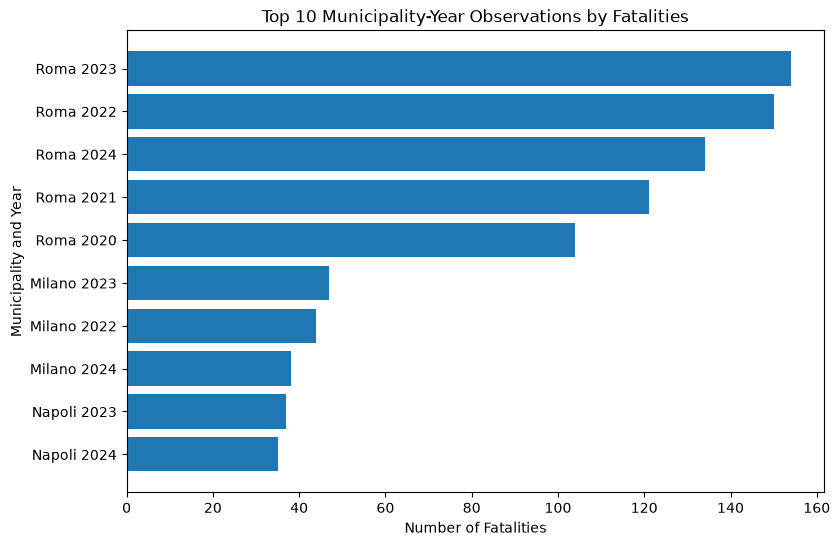

In [46]:
plt.figure(figsize=(9, 6))

labels = (
    top_killed_years["municipality"]
    + " "
    + top_killed_years["TIME_PERIOD"].astype(str)
)

plt.barh(
    labels,
    top_killed_years["killed"]
)

plt.title("Top 10 Municipality-Year Observations by Fatalities")
plt.xlabel("Number of Fatalities")
plt.ylabel("Municipality and Year")

plt.gca().invert_yaxis()

plt.show()

### Fatality extremes

Fatalities are highly concentrated, with most municipality-year observations
recording no deaths.

The highest absolute numbers of fatalities are concentrated mainly in large
municipalities, particularly Rome, Milan and Naples.

These extreme values are retained because they are consistent with municipalities
that also record high numbers of accidents and injuries.

## 9. Relationships Between Variables

This section explores relationships between key numerical variables,
including population, accidents, injuries and fatalities.

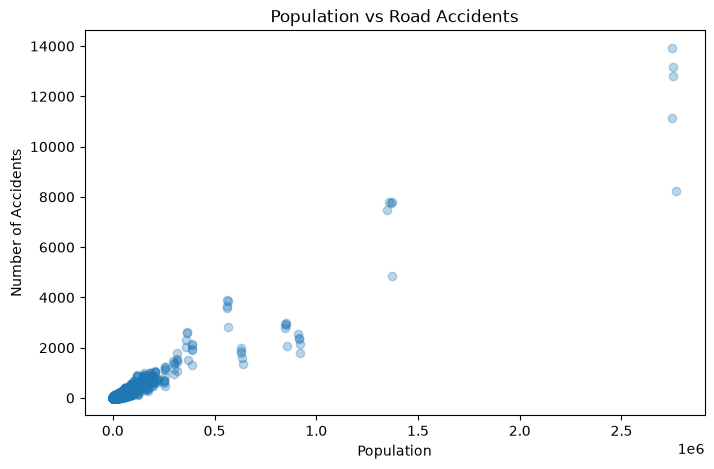

In [47]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df["population"],
    df["accidents"],
    alpha=0.3
)

plt.title("Population vs Road Accidents")
plt.xlabel("Population")
plt.ylabel("Number of Accidents")

plt.show()

In [48]:
df[["population", "accidents"]].corr()

,population,accidents
population,1.000000,0.962945
accidents,0.962945,1.000000


### Population and accidents

Population and road accidents show a strong positive relationship.

More populated municipalities generally record higher numbers of road
accidents. The Pearson correlation between population and accidents is
approximately 0.96.

This indicates a strong linear association, but does not by itself imply
causation.

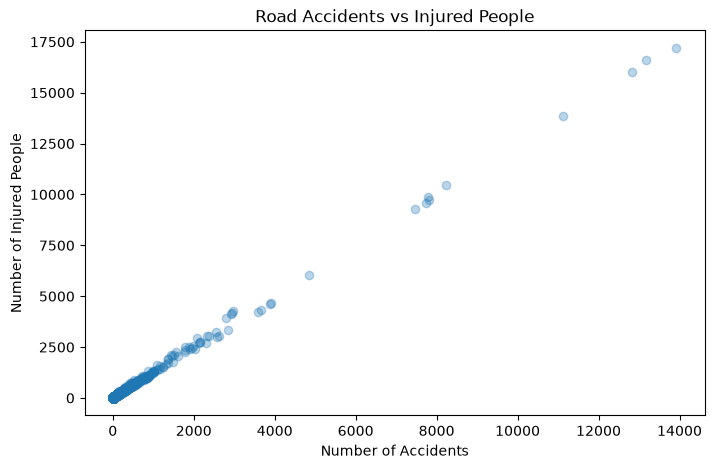

In [49]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df["accidents"],
    df["injured"],
    alpha=0.3
)

plt.title("Road Accidents vs Injured People")
plt.xlabel("Number of Accidents")
plt.ylabel("Number of Injured People")

plt.show()

In [50]:
df[["accidents", "injured"]].corr()

,accidents,injured
accidents,1.000000,0.998996
injured,0.998996,1.000000


### Accidents and injuries

Road accidents and injured people show an extremely strong positive
relationship.

The Pearson correlation is approximately 0.999, indicating that municipalities
and years with more accidents also tend to record proportionally more injured people.

The relationship is almost linear, although the number of injured people
per accident can still vary between observations.

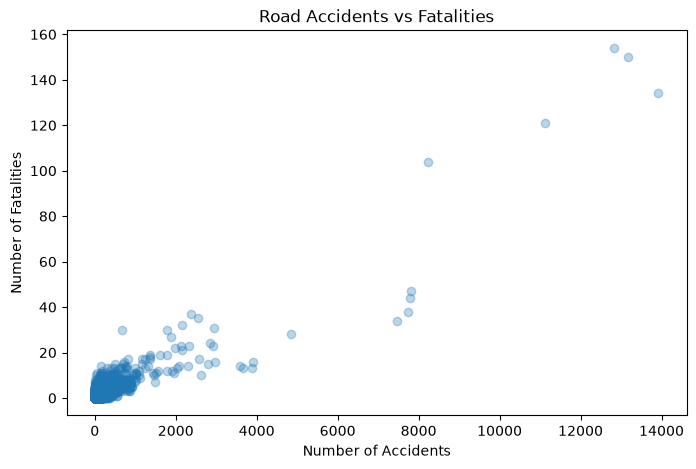

In [51]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df["accidents"],
    df["killed"],
    alpha=0.3
)

plt.title("Road Accidents vs Fatalities")
plt.xlabel("Number of Accidents")
plt.ylabel("Number of Fatalities")

plt.show()

In [52]:
df[["accidents", "killed"]].corr()

,accidents,killed
accidents,1.000000,0.887199
killed,0.887199,1.000000


### Accidents and fatalities

Road accidents and fatalities show a strong positive relationship.

The Pearson correlation is approximately 0.89, indicating that
municipality-year observations with more accidents generally also
record more fatalities.

However, this relationship is weaker than the relationship between
accidents and injured people, showing greater variation in accident severity.

In [53]:
#Correlation Analysis — Relationships Between Numerical Variables

correlation_columns = [
    "population",
    "accidents",
    "injured",
    "killed",
    "accidents_per_100k",
    "accidents_per_km2"
]

correlation_matrix = df[correlation_columns].corr()

correlation_matrix.round(2)

,population,accidents,injured,killed,accidents_per_100k,accidents_per_km2
population,1.00,0.96,0.97,0.90,0.09,0.43
accidents,0.96,1.00,1.00,0.89,0.11,0.43
injured,0.97,1.00,1.00,0.89,0.11,0.43
killed,0.90,0.89,0.89,1.00,0.13,0.32
accidents_per_100k,0.09,0.11,0.11,0.13,1.00,0.26
accidents_per_km2,0.43,0.43,0.43,0.32,0.26,1.00


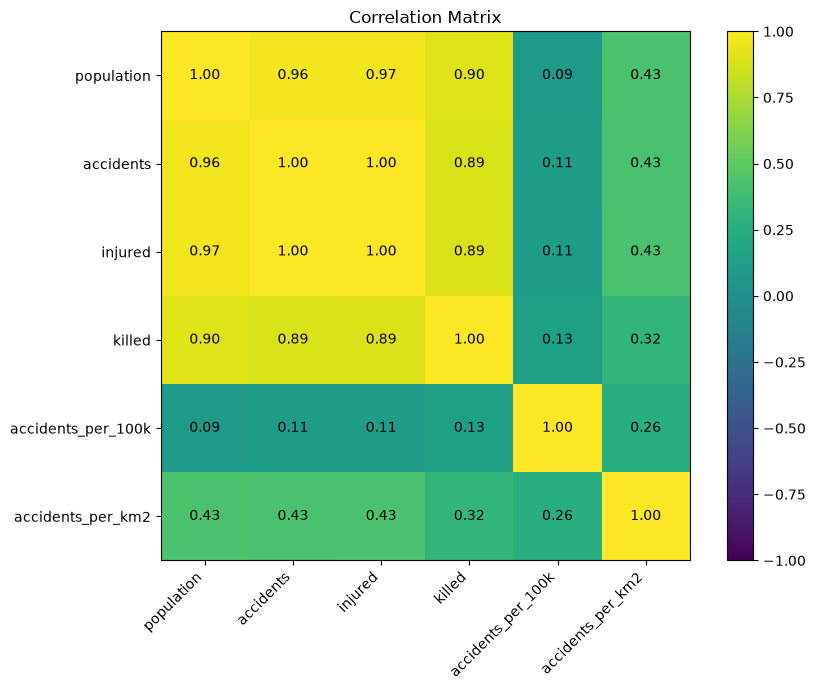

In [54]:
fig, ax = plt.subplots(figsize=(9, 7))

im = ax.imshow(
    correlation_matrix,
    vmin=-1,
    vmax=1
)

ax.set_xticks(range(len(correlation_columns)))
ax.set_yticks(range(len(correlation_columns)))

ax.set_xticklabels(correlation_columns, rotation=45, ha="right")
ax.set_yticklabels(correlation_columns)

for i in range(len(correlation_columns)):
    for j in range(len(correlation_columns)):
        ax.text(
            j,
            i,
            f"{correlation_matrix.iloc[i, j]:.2f}",
            ha="center",
            va="center"
        )

plt.colorbar(im)
plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

### Correlation observations

Population, accidents and injuries show very strong positive correlations.

Fatalities are also positively associated with accident volume, although the
relationship is weaker than for injuries.

The population-adjusted accident rate shows only a weak relationship with
population, suggesting that it provides different information from absolute
accident counts.

Accidents per square kilometre also capture a different dimension of road
accident patterns, reflecting the concentration of accidents within municipal area.

Correlation describes association between variables and does not by itself
demonstrate causation.

## 10. Key Findings

The exploratory analysis identified several important patterns in Italian
road accident data between 2020 and 2024.

- Road accidents increased over the period, with the strongest annual
  increase occurring between 2020 and 2021.

- Injuries followed a similar upward trend, while fatalities increased
  until 2022 and then declined slightly.

- Large municipalities record the highest absolute numbers of accidents,
  injuries and fatalities.

- Population and accident counts are strongly positively correlated,
  showing that more populated municipalities generally record more accidents.

- Accidents and injuries show an almost perfectly linear relationship,
  while the relationship between accidents and fatalities is strong but
  more variable.

- Accident rates per 100,000 residents can become very high in municipalities
  with very small populations. In this exploratory analysis, a minimum
  population threshold is used to reduce the influence of very small
  population denominators.

- Accidents per square kilometre highlight a different pattern, with high
  values concentrated mainly in large or geographically compact urban areas.

- Mortality index rankings are sensitive to the number of accidents used
  in the calculation. In this exploratory analysis, the ranking changes
  substantially when the minimum accident threshold increases from 100
  to 500 accidents.

- The IQR analysis identifies many potential extreme values, but these are
  largely consistent with genuine differences between municipalities rather
  than obvious data errors. Therefore, the observations were retained.

Overall, the analysis shows that absolute accident counts, population-adjusted
rates, accident density and severity indicators provide different perspectives
on road safety and should be interpreted together.